# QQVGA vs QVGA 

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks

pd.set_option('display.float_format', lambda v: f'{v:.4f}')

# ---- Inputs --------------------------------------------------------------
# One entry per working resolution: where its masks were dumped and which
# dataset tree supplied its frames and groundtruth.
RUNS = {
    'qvga': {'dump': Path('results_notebook'), 'data': Path('data_0_1fps')},
    'qqvga': {'dump': Path('results_notebook_qqvga'), 'data': Path('data_0_1fps_qqvga')},
}
CASES = ['busStation', 'canoe']
# Mask kind -> filename suffix inside a dump folder.
MASKS = {'foreground': '_raw', 'filtered': '_morph'}
FG_THRESHOLD = 127  # prediction > this counts as foreground

print('QVGA  masks:', RUNS['qvga']['dump'], ' groundtruth:', RUNS['qvga']['data'])
print('QQVGA masks:', RUNS['qqvga']['dump'], ' groundtruth:', RUNS['qqvga']['data'])
print('cases:', CASES, ' masks:', list(MASKS))

QVGA  masks: results_notebook  groundtruth: data_0_1fps
QQVGA masks: results_notebook_qqvga  groundtruth: data_0_1fps_qqvga
cases: ['busStation', 'canoe']  masks: ['foreground', 'filtered']


## 1. F-measure: QVGA vs QQVGAEach dump is scored against the groundtruth of the dataset it was producedfrom, following the CDNET protocol implemented in `evaluate.accumulate_counts`:only pixels whose groundtruth is exactly `0` or `255` are counted; shadow (50),unknown (85) and outside-ROI (170) pixels are ignored, and frames left with nocountable pixel are skipped.

In [2]:
def index_dump(directory, suffix):
    """Map frame number -> mask path for one dump folder and one mask kind.

    A dump holds both ``<frame>_raw.png`` and ``<frame>_morph.png`` per frame,
    so the suffix is what separates the two mask kinds.
    """
    return {frame_number(p): p for p in sorted(directory.glob(f'*{suffix}.png'))}


def score(mask_index, groundtruth_index):
    """CDNET confusion counts over the frames present in both indexes."""
    tp = fp = fn = tn = frames = 0
    for number, path in sorted(mask_index.items()):
        if number not in groundtruth_index:
            continue
        groundtruth = cv2.imread(str(groundtruth_index[number]), cv2.IMREAD_GRAYSCALE)
        prediction = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(groundtruth, prediction, FG_THRESHOLD)
        if sum(counts) == 0:  # groundtruth is all void for this frame
            continue
        tp, fp, fn, tn = tp + counts[0], fp + counts[1], fn + counts[2], tn + counts[3]
        frames += 1
    return EvaluationResult.from_counts(tp, fp, fn, tn, frames)


def evaluate_run(run, case, mask, groundtruth_run=None):
    """Score one (resolution, case, mask) pair.

    Scores against the run's own groundtruth unless ``groundtruth_run`` names a
    different run, which puts several runs on one common evaluation grid.
    """
    return score(
        index_dump(RUNS[run]['dump'] / case, MASKS[mask]),
        index_masks(RUNS[groundtruth_run or run]['data'] / case / 'groundtruth'),
    )


scores = {
    (run, case, mask): evaluate_run(run, case, mask)
    for run in RUNS
    for case in CASES
    for mask in MASKS
}


def f_measure_table(groundtruth_run=None):
    """Case x (mask, {qvga, qqvga, Δ}) table of F-measures."""
    columns = {}
    for mask in MASKS:
        for run in RUNS:
            columns[(mask, run)] = pd.Series(
                {
                    case: (
                        scores[(run, case, mask)]
                        if groundtruth_run is None
                        else evaluate_run(run, case, mask, groundtruth_run)
                    ).f_measure
                    for case in CASES
                }
            )
        columns[(mask, 'Δ')] = columns[(mask, 'qvga')] - columns[(mask, 'qqvga')]
    table = pd.DataFrame(columns)
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    table.loc['average'] = table.mean()
    return table


f_table = f_measure_table()

### Summary — mean F-measure and its shift under QQVGA`Δ = qvga − qqvga`, so a **positive** value means QVGA scored higher, i.e. it isthe drop caused by working at a quarter of the pixels.

In [3]:
summary = pd.DataFrame(
    {
        mask: {
            'meanF qvga': f_table[(mask, 'qvga')].drop('average').mean(),
            'meanF qqvga': f_table[(mask, 'qqvga')].drop('average').mean(),
            'mean |ΔF|': f_table[(mask, 'Δ')].drop('average').abs().mean(),
            'max |ΔF|': f_table[(mask, 'Δ')].drop('average').abs().max(),
        }
        for mask in MASKS
    }
).T
summary

,meanF qvga,meanF qqvga,mean |ΔF|,max |ΔF|
foreground,0.7187,0.7229,0.0217,0.0259
filtered,0.8664,0.8070,0.0594,0.1021


### Per-case detail (F-measure: QVGA vs QQVGA per case and mask)

In [4]:
f_table

foreground                filtered              
                 qvga  qqvga       Δ     qvga  qqvga      Δ
busStation     0.7261 0.7085  0.0176   0.8068 0.7046 0.1021
canoe          0.7113 0.7372 -0.0259   0.9261 0.9094 0.0167
average        0.7187 0.7229 -0.0041   0.8664 0.8070 0.0594

### Precision / recall behind those F-measuresWhere the F-measure moves, this says whether the pipeline lost detections(recall) or gained false positives (precision) at the lower resolution.

In [5]:
detail = pd.DataFrame(
    [
        {
            'case': case,
            'mask': mask,
            'resolution': run,
            'eval frames': scores[(run, case, mask)].frames,
            'precision': scores[(run, case, mask)].precision,
            'recall': scores[(run, case, mask)].recall,
            'F-measure': scores[(run, case, mask)].f_measure,
            'IoU': scores[(run, case, mask)].iou,
        }
        for case in CASES
        for mask in MASKS
        for run in RUNS
    ]
)
detail.style.format(
    {'precision': '{:.3f}', 'recall': '{:.3f}', 'F-measure': '{:.3f}', 'IoU': '{:.3f}'}
).hide(axis='index').background_gradient(subset=['F-measure'], cmap='RdYlGn', vmin=0, vmax=1)

case,mask,resolution,eval frames,precision,recall,F-measure,IoU
busStation,foreground,qvga,4,0.873,0.622,0.726,0.570
busStation,foreground,qqvga,4,0.972,0.558,0.709,0.549
busStation,filtered,qvga,4,0.988,0.682,0.807,0.676
busStation,filtered,qqvga,4,0.974,0.552,0.705,0.544
canoe,foreground,qvga,1,0.607,0.859,0.711,0.552
canoe,foreground,qqvga,1,0.627,0.893,0.737,0.584
canoe,filtered,qvga,1,0.917,0.935,0.926,0.862
canoe,filtered,qqvga,1,0.879,0.942,0.909,0.834


### Control: both scored on the same gridAbove, each side is scored against its own groundtruth, so the QVGA numbers arecomputed over ~76 800 pixels and the QQVGA ones over 19 200. That is the naturalreading, but it means the two F-measures are not measured on identical grids.Here **both** mask sets are scored against the **QQVGA groundtruth**, puttingthem on one common grid and isolating the resolution effect from theevaluation-grid effect. If this table agrees with the one above, the shift isreal rather than an artefact of the scoring resolution.

In [6]:
f_table_common = f_measure_table(groundtruth_run='qqvga')
f_table_common

foreground                filtered              
                 qvga  qqvga       Δ     qvga  qqvga      Δ
busStation     0.7262 0.7085  0.0177   0.8073 0.7046 0.1027
canoe          0.7098 0.7372 -0.0274   0.9260 0.9094 0.0166
average        0.7180 0.7229 -0.0048   0.8666 0.8070 0.0596

## 2. Mask difference: QVGA vs QQVGAFor each matched frame the QVGA and QQVGA masks are compared pixel by pixel(both first resized to the smaller size, 160x120, with nearest-neighbour). Thevalue is the mean fraction of differing pixels, as a percentage — a directmeasure of how much the output itself changed, independent of any groundtruth.

In [7]:
def align(mask_a, mask_b):
    """Resize both boolean masks to the smaller size (nearest-neighbour)."""
    if mask_a.shape == mask_b.shape:
        return mask_a, mask_b
    height, width = mask_a.shape if mask_a.size <= mask_b.size else mask_b.shape
    fit = lambda m: cv2.resize(
        m.astype(np.uint8), (width, height), interpolation=cv2.INTER_NEAREST
    ) > 0
    return fit(mask_a), fit(mask_b)


def mask_difference(case, mask):
    """Mean % of pixels differing between the QVGA and QQVGA masks of a case."""
    a = index_dump(RUNS['qvga']['dump'] / case, MASKS[mask])
    b = index_dump(RUNS['qqvga']['dump'] / case, MASKS[mask])
    per_frame = []
    for number in sorted(set(a) & set(b)):
        mask_a = cv2.imread(str(a[number]), cv2.IMREAD_GRAYSCALE) > FG_THRESHOLD
        mask_b = cv2.imread(str(b[number]), cv2.IMREAD_GRAYSCALE) > FG_THRESHOLD
        mask_a, mask_b = align(mask_a, mask_b)
        per_frame.append(float((mask_a != mask_b).mean()))
    return float(np.mean(per_frame)) * 100.0 if per_frame else np.nan


diff_table = pd.DataFrame(
    {mask: {case: mask_difference(case, mask) for case in CASES} for mask in MASKS}
)
diff_table.loc['average'] = diff_table.mean()
diff_table

,foreground,filtered
busStation,0.8047,0.5807
canoe,3.2135,0.7010
average,2.0091,0.6409


### Headline numbers

In [8]:
for mask in MASKS:
    mean_df = f_table[(mask, 'Δ')].drop('average').abs().mean()
    mean_mask = diff_table.loc['average', mask]
    print(f'{mask:11s} mean |ΔF| = {mean_df:.4f}   mean mask difference = {mean_mask:.3f} %')

foreground  mean |ΔF| = 0.0217   mean mask difference = 2.009 %
filtered    mean |ΔF| = 0.0594   mean mask difference = 0.641 %


## 3. Graphs

### F-measure: QVGA vs QQVGA, per case and mask

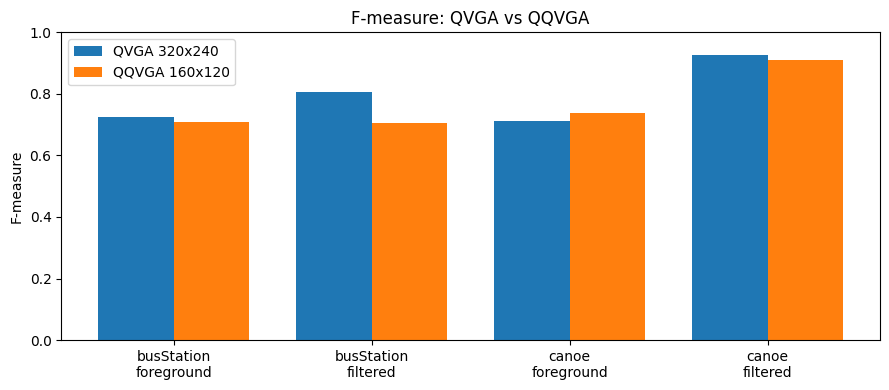

In [9]:
labels = [f'{case}\n{mask}' for case in CASES for mask in MASKS]
qvga = [f_table.loc[case, (mask, 'qvga')] for case in CASES for mask in MASKS]
qqvga = [f_table.loc[case, (mask, 'qqvga')] for case in CASES for mask in MASKS]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(labels))
width = 0.38
ax.bar(x - width / 2, qvga, width, label='QVGA 320x240')
ax.bar(x + width / 2, qqvga, width, label='QQVGA 160x120')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('F-measure')
ax.set_ylim(0, 1)
ax.set_title('F-measure: QVGA vs QQVGA')
ax.legend()
plt.tight_layout()
plt.show()

### Mask difference (%) per case and mask

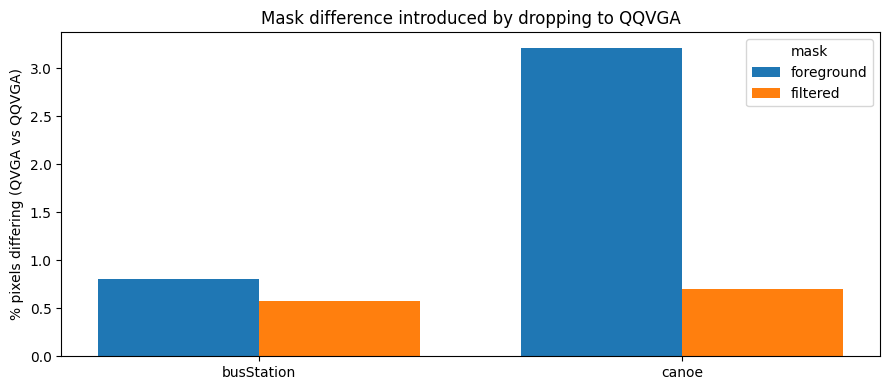

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(CASES))
width = 0.38
for offset, mask in zip((-0.5, 0.5), MASKS):
    ax.bar(x + offset * width, [diff_table.loc[c, mask] for c in CASES], width, label=mask)
ax.set_xticks(x)
ax.set_xticklabels(CASES)
ax.set_ylabel('% pixels differing (QVGA vs QQVGA)')
ax.set_title('Mask difference introduced by dropping to QQVGA')
ax.legend(title='mask')
plt.tight_layout()
plt.show()

## 4. Side by side — input | filtered mask QVGA | filtered mask QQVGAOne row per frame: the source frame, then the pipeline's final (`filtered`)mask at each working resolution. Each panel is labelled with its own pixel size;matplotlib scales them to a common panel, so the visible difference is genuinedetail loss and not a plotting artefact.Set `SHOW_MASK = 'foreground'` to compare the raw model output instead.

In [11]:
SHOW_MASK = 'filtered'  # 'filtered' (post-morphology) or 'foreground' (raw model output)


def source_frame(case, mask_path):
    """Load the input frame a dumped mask was produced from."""
    stem = mask_path.stem.replace(MASKS[SHOW_MASK], '')
    matches = sorted((RUNS['qvga']['data'] / case / 'input').glob(f'{stem}.*'))
    return cv2.imread(str(matches[0]), cv2.IMREAD_COLOR) if matches else None


def show_side_by_side(case):
    """Per frame: source input, filtered mask at QVGA, filtered mask at QQVGA."""
    qvga_masks = index_dump(RUNS['qvga']['dump'] / case, MASKS[SHOW_MASK])
    qqvga_masks = index_dump(RUNS['qqvga']['dump'] / case, MASKS[SHOW_MASK])
    numbers = sorted(set(qvga_masks) & set(qqvga_masks))

    fig, axes = plt.subplots(len(numbers), 3, figsize=(11, 2.7 * len(numbers)))
    axes = np.atleast_2d(axes)
    for row, number in enumerate(numbers):
        image = source_frame(case, qvga_masks[number])
        panels = [
            (None if image is None else image[:, :, ::-1], 'input'),
            (cv2.imread(str(qvga_masks[number]), cv2.IMREAD_GRAYSCALE), f'{SHOW_MASK} — QVGA'),
            (cv2.imread(str(qqvga_masks[number]), cv2.IMREAD_GRAYSCALE), f'{SHOW_MASK} — QQVGA'),
        ]
        for column, (panel, title) in enumerate(panels):
            ax = axes[row][column]
            if panel is None:
                ax.axis('off')
                continue
            if panel.ndim == 3:
                ax.imshow(panel)
            else:
                ax.imshow(panel, cmap='gray', vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                height, width = panel.shape[:2]
                ax.set_title(f'{title}\n{width}x{height}', fontsize=10)
            if column == 0:
                ax.set_ylabel(f'frame #{number}', fontsize=10)
    fig.suptitle(f'{case} — input vs {SHOW_MASK} mask at both resolutions', fontsize=13)
    fig.tight_layout()
    plt.show()

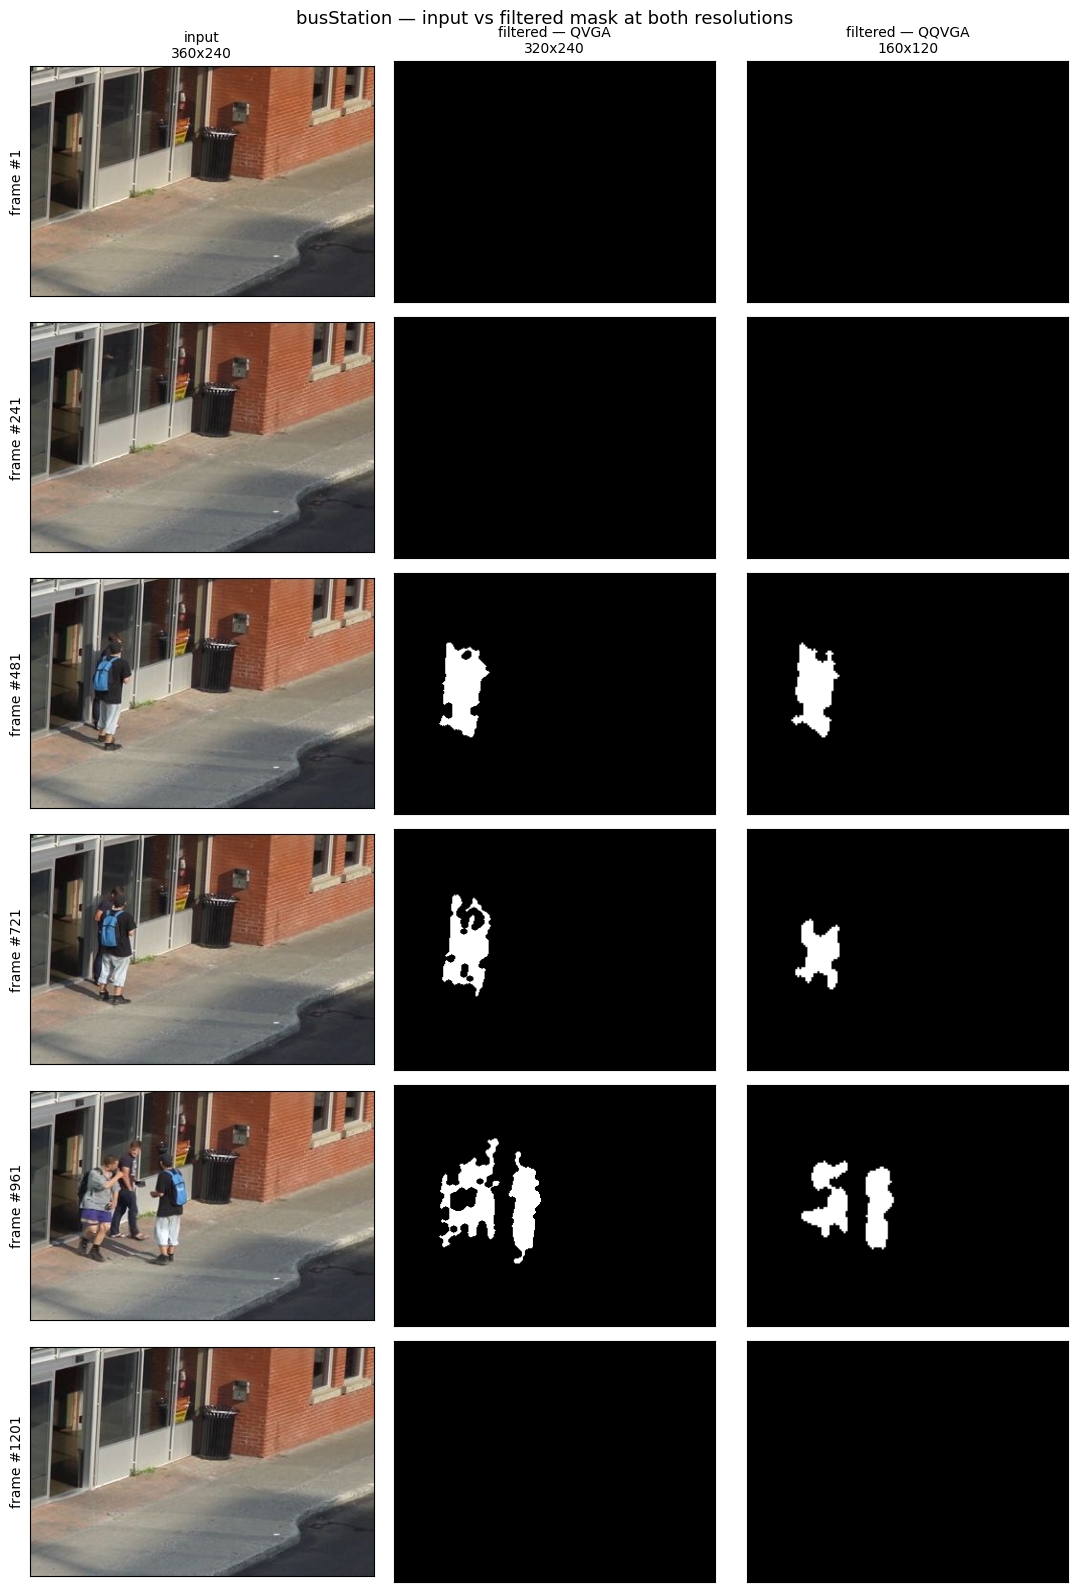

In [12]:
show_side_by_side('busStation')

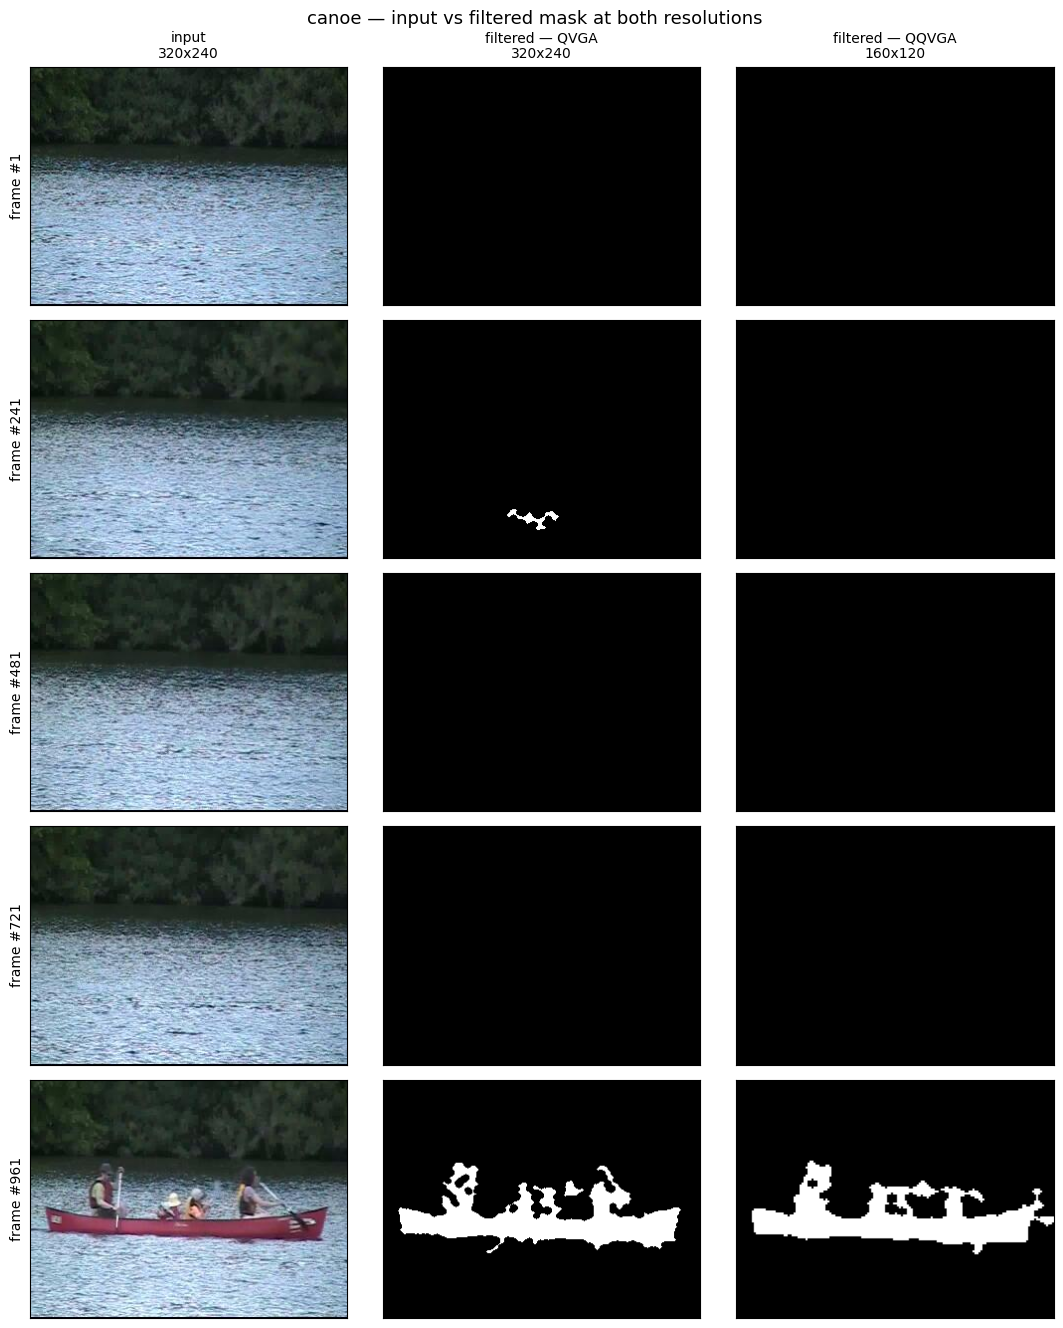

In [13]:
show_side_by_side('canoe')

## 5. Notes* **Scope.** Two cases and 11 frames in total (busStation 6, canoe 5), of which  only the frames with non-void groundtruth are scored — see `eval frames` in the  precision/recall table. The numbers are indicative of the resolution effect,  not a statistically tight benchmark; rerun `pipeline_experiments.ipynb` over a  denser dataset and point `RUNS` at the new dumps for a fuller picture.* **Resolution-coupled thresholds.** `BLOB.min_area` (150 px) and  `SOL_AREA_THRESHOLD` (500 px) are absolute pixel counts, so at QQVGA they gate  4x harder relative to the frame. Both dumps here use the same values, so part  of the `filtered` difference is that stricter gate rather than segmentation  quality; the `foreground` mask is not area-gated and isolates the model.* **Morphology is resolution-coupled too.** The 3 px opening and 7 px closing  kernels cover 4x more of the frame at QQVGA, which is the second such knob.* **Alignment rule.** Wherever two masks (or a mask and its groundtruth) differ  in size they are resized to the smaller one with nearest-neighbour, matching  `evaluate.resize_to_smallest`, so no interpolation invents intermediate values.